# Predicting Player Retention/ Engagement

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
np.random.seed(4)

In [8]:
player_data = pd.read_csv('online_gaming_behavior_dataset.csv')
player_data.head()

,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium


In [23]:
num_to_cat = ["Medium", "High", "Low"]

# Drops ID and target variable cols
X = player_data.drop(columns=['PlayerID','EngagementLevel'])

# Lists out categorical cols
categorical_cols = ['Gender', 'Location', 'GameGenre', 'GameDifficulty']

# Stacks categorical Cols
stacked_cat = X[categorical_cols].stack()
# Factorizes necessary cols
factorized = pd.Series(stacked_cat.factorize()[0], index=stacked_cat.index)
# Adds numerical cols back to X
X[categorical_cols] = factorized.unstack()
X = X.to_numpy()

# Adds Bias Col
ones = np.ones((X.shape[0], 1))
X = np.hstack([ones, X])

In [10]:
# Change Engagement Level to numeric values
y = pd.factorize(player_data['EngagementLevel'])[0]
y = np.eye(3)[y]
y

array([[1., 0., 0.],
       [1., 0., 0.],
       [0., 1., 0.],
       ...,
       [0., 1., 0.],
       [1., 0., 0.],
       [1., 0., 0.]], shape=(40034, 3))

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2)
X_train = (X_train - X_train.mean(axis=0))


In [12]:
eta = .05
q = 15
p = 12

W1 = np.random.randn(p, q) * np.sqrt(2/p)
W2 = np.random.randn(q, 3) * np.sqrt(2/q)

In [13]:
def softmax(z):
    expz = np.exp(z - np.max(z))
    return expz / np.sum(expz)

In [14]:
def f(x):
    h = np.maximum(0, W1.T @ x)  
    z = W2.T @ h
    return softmax(z)

In [15]:
errors = []
test_errors = []
best_W1 = W1
best_W2 = W2
best_test_loss = np.inf

limit = 5
epochs = 50
n = X_train.shape[0]

for epoch in range(epochs):
    dW2 = np.zeros_like(W2)
    # Performs backprop for ReLU W2
    for i, j in enumerate(y_train):
        x = np.reshape(X_train[i], (p,1))
        yi = y_train[i].reshape(3,1)
        h = np.maximum(0, W1.T.dot(x))
        dW2 += (2/n) * h @ (f(x) - yi).T
        
    # Updates W2
    W2 = W2 - eta * dW2
    
    dW1 = np.zeros_like(W1)
    # Performs backprop for ReLU W1
    for i, j in enumerate(y_train):
        x = np.reshape(X_train[i], (p,1))
        h = np.maximum(0, W1.T.dot(x))
        mat1 = np.heaviside(h, 0)

        yi = y_train[i].reshape(3,1)
        delta1 = (W2 @ (f(x) - yi)) * mat1
        dW1 += (2/n) * x @ delta1.T

    # Updates W1
    W1 = W1 - eta * dW1

    pred = f(X_train.T)
    print("Epoch", epoch)
    e = -(1/n) * np.sum(y_train.T * np.log(pred + 1e-12))
    errors.append(e)

    pred_test = f(X_test.T)
    n_test = X_test.shape[0]
    test_loss = -(1/n_test) * np.sum(y_test.T * np.log(pred_test + 1e-12))
    test_errors.append(test_loss)
    
    if test_loss < best_test_loss:
        best_test_loss = test_loss
        wait = 0
        best_W1 = W1.copy()
        best_W2 = W2.copy()
    else:
        wait += 1
        if wait >= limit:
            print("Early stopping at epoch", epoch)
            W1 = best_W1
            W2 = best_W2
            break


Epoch 0
Epoch 1
Epoch 2
Epoch 3
Epoch 4
Epoch 5
Epoch 6
Epoch 7
Epoch 8
Early stopping at epoch 8


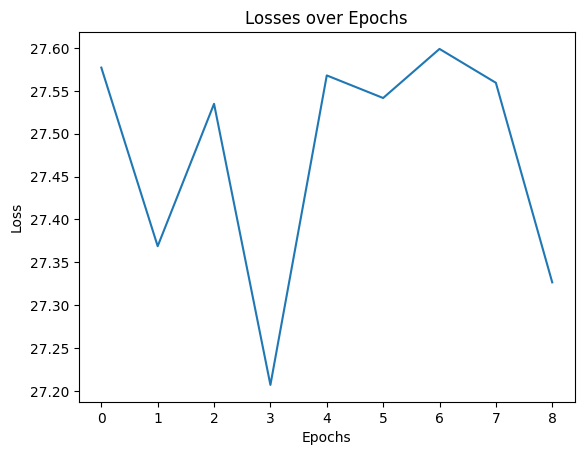

In [16]:
plt.plot(range(len(test_errors)), test_errors, label='line')
plt.title("Losses over Epochs")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

In [ ]:
pred_test = f(X_test.T)
y_pred = np.argmax(pred_test, axis=0)
y_true = np.argmax(y_test, axis=1)

accuracy = np.mean(y_pred == y_true)
print("Test Accuracy:", accuracy)

Test Accuracy: 0.5132794937973524


In [24]:
pred_test = f(X_test[0])
y_pred = np.argmax(pred_test, axis=0)
print("Predicted Engagement level:", num_to_cat[y_pred])
print("Actual Engagement Level:", num_to_cat[np.argmax(y_test[0])])

Predicted Engagement level: Medium
Actual Engagement Level: High
